# Dataset 4 for analysis/demonstration

## Part 1: Test set (10%) MSE Comparsion for 30% (aug), 60%(non-aug/"true"), 90% (all training)

In [1]:
from gauche.dataloader import MolPropLoader

loader = MolPropLoader()
loader.load_benchmark("Photoswitch")

Found 13 invalid labels [nan nan nan nan nan nan nan nan nan nan nan nan nan] at indices [41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 158]
To turn validation off, use dataloader.read_csv(..., validate=False).


In [2]:
loader.featurize("ecfp_fingerprints")
loader.features

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 1, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 1]], shape=(392, 2048))

In [3]:
X = loader.features
y = loader.labels

In [4]:
from crda_gp.utils import set_seed
from sklearn.model_selection import train_test_split
import torch


set_seed(42)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

# Turn the data splits into torch.Tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).squeeze()
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).squeeze()

In [5]:
from crda_gp.models import ARDExactGPModel_Sparse
import gpytorch
set_seed(42)
likelihood = gpytorch.likelihoods.GaussianLikelihood()
model = ARDExactGPModel_Sparse(train_x=X_train_tensor,
                               train_y=y_train_tensor,
                               likelihood=likelihood)

In [6]:
from crda_gp.utils import train_step
set_seed(42)
train_step(X_train=X_train_tensor,
           y_train=y_train_tensor,
           model=model,
           likelihood=likelihood)

Iter: 10/100 | Loss: 1547.924 | Noise: 1.284
Iter: 20/100 | Loss: 992.173 | Noise: 1.911
Iter: 30/100 | Loss: 659.858 | Noise: 2.441
Iter: 40/100 | Loss: 437.653 | Noise: 2.859
Iter: 50/100 | Loss: 329.543 | Noise: 3.191
Iter: 60/100 | Loss: 278.064 | Noise: 3.468
Iter: 70/100 | Loss: 249.394 | Noise: 3.713
Iter: 80/100 | Loss: 230.636 | Noise: 3.942
Iter: 90/100 | Loss: 216.793 | Noise: 4.160
Iter: 100/100 | Loss: 205.739 | Noise: 4.371


In [7]:
from crda_gp.utils import val_step
set_seed(42)
y_pred = val_step(X_test=X_test_tensor,
                  model=model,
                  likelihood=likelihood)

In [8]:
from sklearn.metrics import mean_squared_error
set_seed(42)
MSE = mean_squared_error(y_true=y_test_tensor, 
                         y_pred=y_pred)

In [9]:
MSE

722.8248291015625

In [10]:
# Splitting the train data into augment and true values respectively
X_train_aug, X_train_true, y_train_aug, y_train_true = train_test_split(X_train, y_train, test_size=(0.6*len(X)/len(X_train)), random_state=42)
# Change the data into tensors
X_train_aug_tensor = torch.tensor(X_train_aug, dtype=torch.float32)
X_train_true_tensor = torch.tensor(X_train_true, dtype=torch.float32)
y_train_aug_tensor = torch.tensor(y_train_aug, dtype=torch.float32).squeeze()
y_train_true_tensor = torch.tensor(y_train_true, dtype=torch.float32).squeeze()

In [11]:
likelihood_true = gpytorch.likelihoods.GaussianLikelihood()
model_true = ARDExactGPModel_Sparse(train_x=X_train_true_tensor,
                                   train_y=y_train_true_tensor,
                                   likelihood=likelihood_true)

In [12]:
train_step(X_train=X_train_true_tensor, 
           y_train=y_train_true_tensor,
           model=model_true,
           likelihood=likelihood_true)

Iter: 10/100 | Loss: 2102.309 | Noise: 1.284
Iter: 20/100 | Loss: 1354.209 | Noise: 1.912
Iter: 30/100 | Loss: 909.342 | Noise: 2.447
Iter: 40/100 | Loss: 598.602 | Noise: 2.869
Iter: 50/100 | Loss: 444.335 | Noise: 3.201
Iter: 60/100 | Loss: 371.458 | Noise: 3.474
Iter: 70/100 | Loss: 331.478 | Noise: 3.713
Iter: 80/100 | Loss: 305.694 | Noise: 3.933
Iter: 90/100 | Loss: 286.876 | Noise: 4.142
Iter: 100/100 | Loss: 271.964 | Noise: 4.343


In [13]:
y_pred_true = val_step(X_test=X_test_tensor, 
                       model=model_true, 
                       likelihood=likelihood_true)

In [14]:
MSE_true = mean_squared_error(y_test_tensor, y_pred_true)
MSE_true

823.8798828125

In [15]:
MSE

722.8248291015625

In [16]:
likelihood_aug = gpytorch.likelihoods.GaussianLikelihood()
model_aug = ARDExactGPModel_Sparse(train_x=X_train_aug_tensor, 
                                  train_y=y_train_aug_tensor, 
                                  likelihood=likelihood_aug)

In [17]:
train_step(X_train=X_train_aug_tensor, 
           y_train=y_train_aug_tensor,
           model=model_aug,
           likelihood=likelihood_aug)

Iter: 10/100 | Loss: 3597.781 | Noise: 1.284
Iter: 20/100 | Loss: 2360.955 | Noise: 1.912
Iter: 30/100 | Loss: 1819.128 | Noise: 2.445
Iter: 40/100 | Loss: 1535.539 | Noise: 2.871
Iter: 50/100 | Loss: 1362.425 | Noise: 3.216
Iter: 60/100 | Loss: 1243.269 | Noise: 3.510
Iter: 70/100 | Loss: 1153.802 | Noise: 3.769
Iter: 80/100 | Loss: 1082.519 | Noise: 4.006
Iter: 90/100 | Loss: 1023.430 | Noise: 4.226
Iter: 100/100 | Loss: 973.121 | Noise: 4.433


In [18]:
y_pred_aug = val_step(X_test=X_test_tensor, 
                      model=model_aug, 
                      likelihood=likelihood_aug)

In [19]:
MSE_aug = mean_squared_error(y_test_tensor, y_pred_aug)
MSE_aug

4757.0439453125

In [20]:
MSE

722.8248291015625

In [21]:
import pandas as pd
with torch.no_grad(), gpytorch.settings.fast_pred_var():
    pred_dist = likelihood_aug(model_aug(X_train_aug_tensor))
    y_new_aug = pred_dist.mean

residual = y_train_aug_tensor - y_new_aug
corr = abs(pd.DataFrame(X_train).corrwith(pd.Series(residual)))

preturb_idx= corr[abs(corr) < corr.mean().item()].sort_values(ascending=False).index.values
len(preturb_idx)

c:\Users\bandarua\crda_gp\env\Lib\site-packages\gpytorch\models\exact_gp.py:299: GPInputWarning: The input matches the stored training data. Did you forget to call model.train()?
  warnings.warn(
c:\Users\bandarua\crda_gp\env\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\bandarua\crda_gp\env\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
c:\Users\bandarua\crda_gp\env\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\bandarua\crda_gp\env\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
c:\Users\bandarua\crda_gp\env\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, 

443

In [22]:
from crda_gp.crda import CRDA_function
X_train_aug_CRDA_tensor, y_train_aug_CRDA_tensor, _, _ = CRDA_function(X_train_aug_tensor, 
                                                                 y_train_aug_tensor, 
                                                                 model=model_aug, 
                                                                 likelihood=likelihood_aug, 
                                                                 perturb_idx=preturb_idx, 
                                                                 p=0.1)

c:\Users\bandarua\crda_gp\env\Lib\site-packages\gpytorch\models\exact_gp.py:299: GPInputWarning: The input matches the stored training data. Did you forget to call model.train()?
  warnings.warn(


Starting the Loop
Iter: 0
Iter: 1
Iter: 2
Iter: 3
Iter: 4
Iter: 5
Iter: 6
Iter: 7
Iter: 8
Iter: 9
Iter: 10
Iter: 11
Iter: 12
Iter: 13
Iter: 14
Iter: 15
Iter: 16
Iter: 17
Iter: 18
Iter: 19
Iter: 20
Iter: 21
Iter: 22
Iter: 23
Iter: 24
Iter: 25
Iter: 26
Iter: 27
Iter: 28
Iter: 29
Iter: 30
Iter: 31
Iter: 32
Iter: 33
Iter: 34
Iter: 35
Iter: 36
Iter: 37
Iter: 38
Iter: 39
Iter: 40
Iter: 41
Iter: 42
Iter: 43
Iter: 44
Iter: 45
Iter: 46
Iter: 47
Iter: 48
Iter: 49
Iter: 50
Iter: 51
Iter: 52
Iter: 53
Iter: 54
Iter: 55
Iter: 56
Iter: 57
Iter: 58
Iter: 59
Iter: 60
Iter: 61
Iter: 62
Iter: 63
Iter: 64
Iter: 65
Iter: 66
Iter: 67
Iter: 68
Iter: 69
Iter: 70
Iter: 71
Iter: 72
Iter: 73
Iter: 74
Iter: 75
Iter: 76
Iter: 77
Iter: 78
Iter: 79
Iter: 80
Iter: 81
Iter: 82
Iter: 83
Iter: 84
Iter: 85
Iter: 86
Iter: 87
Iter: 88
Iter: 89
Iter: 90
Iter: 91
Iter: 92
Iter: 93
Iter: 94
Iter: 95
Iter: 96
Iter: 97
Iter: 98
Iter: 99
Iter: 100
Iter: 101
Iter: 102
Iter: 103
Iter: 104
Iter: 105
Iter: 106
Iter: 107
Iter: 108
It

In [23]:
likelihood_aug_new = gpytorch.likelihoods.GaussianLikelihood()
model_aug_new = ARDExactGPModel_Sparse(train_x=X_train_aug_CRDA_tensor, 
                                      train_y=y_train_aug_CRDA_tensor, 
                                      likelihood=likelihood_aug_new)

In [24]:
train_step(X_train=X_train_aug_CRDA_tensor, 
           y_train=y_train_aug_CRDA_tensor,
           model=model_aug_new,
           likelihood=likelihood_aug_new)

Iter: 10/100 | Loss: 1860.601 | Noise: 1.284
Iter: 20/100 | Loss: 1203.895 | Noise: 1.913
Iter: 30/100 | Loss: 815.404 | Noise: 2.449
Iter: 40/100 | Loss: 533.329 | Noise: 2.875
Iter: 50/100 | Loss: 391.415 | Noise: 3.210
Iter: 60/100 | Loss: 325.110 | Noise: 3.485
Iter: 70/100 | Loss: 289.256 | Noise: 3.726
Iter: 80/100 | Loss: 266.404 | Noise: 3.948
Iter: 90/100 | Loss: 249.861 | Noise: 4.159
Iter: 100/100 | Loss: 236.817 | Noise: 4.363


In [25]:
y_pred_aug_new = val_step(X_test=X_test_tensor, 
                      model=model_aug_new, 
                      likelihood=likelihood_aug_new)

In [26]:
MSE_aug_new = mean_squared_error(y_test_tensor, y_pred_aug_new)
MSE_aug_new

1448.4674072265625

In [27]:
MSE_aug

4757.0439453125

In [28]:
MSE_true

823.8798828125

In [29]:
MSE

722.8248291015625

In [30]:
MSE_true_percentage = ((MSE_true - MSE)/MSE)*100
MSE_true_percentage

13.98057311292754

In [31]:
MSE_aug_percentage = ((MSE_aug - MSE)/MSE)*100
MSE_aug_percentage

558.1185030991926

In [32]:
MSE_aug_new_percentage = ((MSE_aug_new - MSE)/MSE)*100
MSE_aug_new_percentage

100.38982460341599

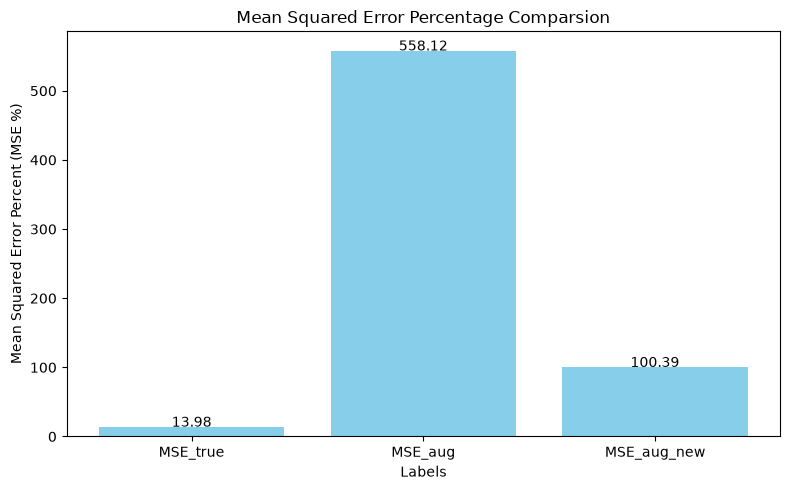

In [33]:
import matplotlib.pyplot as plt

# Example data
MSE_results_labels = ['MSE_true', 'MSE_aug', 'MSE_aug_new']
MSE_results_values = [MSE_true_percentage, MSE_aug_percentage, MSE_aug_new_percentage]

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(MSE_results_labels, MSE_results_values, color='skyblue')

plt.title('Mean Squared Error Percentage Comparsion')
plt.xlabel('Labels')
plt.ylabel('Mean Squared Error Percent (MSE %)')

# Add value labels on bars
for i, values in enumerate(MSE_results_values):
    plt.text(i, values + 0.2, f'{values:.2f}', ha='center')

plt.tight_layout()
plt.show()

## Part 2: Informative metric testing 

In [34]:
import torch

X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32).squeeze()

In [35]:
set_seed(42)
likelihood = gpytorch.likelihoods.GaussianLikelihood()
model = ARDExactGPModel_Sparse(train_x=X_tensor,
                              train_y=y_tensor,
                              likelihood=likelihood)

In [36]:
set_seed(42)
train_step(X_train=X_tensor,
           y_train=y_tensor,
           model=model,
           likelihood=likelihood)

Iter: 10/100 | Loss: 1418.661 | Noise: 1.284
Iter: 20/100 | Loss: 906.917 | Noise: 1.910
Iter: 30/100 | Loss: 600.606 | Noise: 2.440
Iter: 40/100 | Loss: 399.849 | Noise: 2.858
Iter: 50/100 | Loss: 302.656 | Noise: 3.190
Iter: 60/100 | Loss: 256.067 | Noise: 3.469
Iter: 70/100 | Loss: 229.930 | Noise: 3.718
Iter: 80/100 | Loss: 212.737 | Noise: 3.949
Iter: 90/100 | Loss: 200.006 | Noise: 4.170
Iter: 100/100 | Loss: 189.822 | Noise: 4.383


In [37]:
X_CRDA_tensor, y_CRDA_tensor, _, _ = CRDA_function(X_train=X_tensor,
                                             y_train=y_tensor,
                                             model=model,
                                             likelihood=likelihood)

c:\Users\bandarua\crda_gp\env\Lib\site-packages\gpytorch\models\exact_gp.py:299: GPInputWarning: The input matches the stored training data. Did you forget to call model.train()?
  warnings.warn(


Starting the Loop
Iter: 0
Iter: 1
Iter: 2
Iter: 3
Iter: 4
Iter: 5
Iter: 6
Iter: 7
Iter: 8
Iter: 9
Iter: 10
Iter: 11
Iter: 12
Iter: 13
Iter: 14
Iter: 15
Iter: 16
Iter: 17
Iter: 18
Iter: 19
Iter: 20
Iter: 21
Iter: 22
Iter: 23
Iter: 24
Iter: 25
Iter: 26
Iter: 27
Iter: 28
Iter: 29
Iter: 30
Iter: 31
Iter: 32
Iter: 33
Iter: 34
Iter: 35
Iter: 36
Iter: 37
Iter: 38
Iter: 39
Iter: 40
Iter: 41
Iter: 42
Iter: 43
Iter: 44
Iter: 45
Iter: 46
Iter: 47
Iter: 48
Iter: 49
Iter: 50
Iter: 51
Iter: 52
Iter: 53
Iter: 54
Iter: 55
Iter: 56
Iter: 57
Iter: 58
Iter: 59
Iter: 60
Iter: 61
Iter: 62
Iter: 63
Iter: 64
Iter: 65
Iter: 66
Iter: 67
Iter: 68
Iter: 69
Iter: 70
Iter: 71
Iter: 72
Iter: 73
Iter: 74
Iter: 75
Iter: 76
Iter: 77
Iter: 78
Iter: 79
Iter: 80
Iter: 81
Iter: 82
Iter: 83
Iter: 84
Iter: 85
Iter: 86
Iter: 87
Iter: 88
Iter: 89
Iter: 90
Iter: 91
Iter: 92
Iter: 93
Iter: 94
Iter: 95
Iter: 96
Iter: 97
Iter: 98
Iter: 99
Iter: 100
Iter: 101
Iter: 102
Iter: 103
Iter: 104
Iter: 105
Iter: 106
Iter: 107
Iter: 108
It

In [38]:
from crda_gp.utils import entropy_cal
entropies_true = entropy_cal(X=X_tensor)

In [39]:
entropies_aug = entropy_cal(X=X_CRDA_tensor)

Mean of True vs Aug: 0.09190202995207492 | 0.09191810897986868


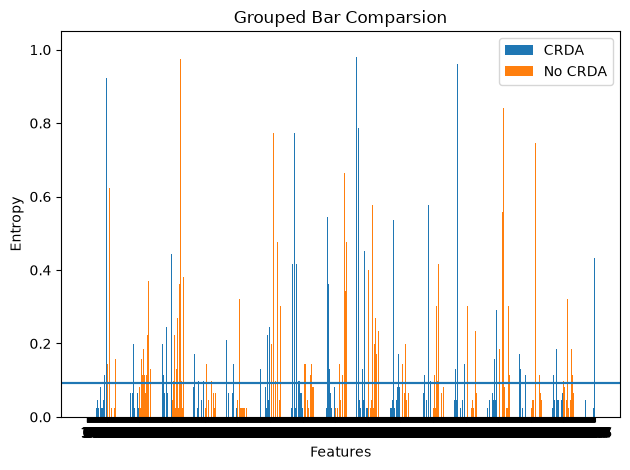

In [40]:
from crda_gp.utils import plot_comparsion_entropies
plot_comparsion_entropies(X_tensor,
                          entropy_1=entropies_aug,
                          entropy_2=entropies_true)

## Part 3: Random Benchmarking vs CRDA

In [41]:
from crda_gp.crda import random_benchmark
X_random_tensor, y_random_tensor = random_benchmark(X_train=X_train_aug_tensor,
                                                    y_train=y_train_aug_tensor,
                                                    model=model_aug,
                                                    likelihood=likelihood_aug,
                                                    perturb_idx=preturb_idx,
                                                    p=0.1)

Starting the Loop
Iter: 0
Iter: 1
Iter: 2
Iter: 3
Iter: 4
Iter: 5
Iter: 6
Iter: 7
Iter: 8
Iter: 9
Iter: 10
Iter: 11
Iter: 12
Iter: 13
Iter: 14
Iter: 15
Iter: 16
Iter: 17
Iter: 18
Iter: 19
Iter: 20
Iter: 21
Iter: 22
Iter: 23
Iter: 24
Iter: 25
Iter: 26
Iter: 27
Iter: 28
Iter: 29
Iter: 30
Iter: 31
Iter: 32
Iter: 33
Iter: 34
Iter: 35
Iter: 36
Iter: 37
Iter: 38
Iter: 39
Iter: 40
Iter: 41
Iter: 42
Iter: 43
Iter: 44
Iter: 45
Iter: 46
Iter: 47
Iter: 48
Iter: 49
Iter: 50
Iter: 51
Iter: 52
Iter: 53
Iter: 54
Iter: 55
Iter: 56
Iter: 57
Iter: 58
Iter: 59
Iter: 60
Iter: 61
Iter: 62
Iter: 63
Iter: 64
Iter: 65
Iter: 66
Iter: 67
Iter: 68
Iter: 69
Iter: 70
Iter: 71
Iter: 72
Iter: 73
Iter: 74
Iter: 75
Iter: 76
Iter: 77
Iter: 78
Iter: 79
Iter: 80
Iter: 81
Iter: 82
Iter: 83
Iter: 84
Iter: 85
Iter: 86
Iter: 87
Iter: 88
Iter: 89
Iter: 90
Iter: 91
Iter: 92
Iter: 93
Iter: 94
Iter: 95
Iter: 96
Iter: 97
Iter: 98
Iter: 99
Iter: 100
Iter: 101
Iter: 102
Iter: 103
Iter: 104
Iter: 105
Iter: 106
Iter: 107
Iter: 108
It

In [42]:
set_seed(42)
likelihood_random = gpytorch.likelihoods.GaussianLikelihood()
model_random = ARDExactGPModel_Sparse(train_x=X_random_tensor,
                                     train_y=y_random_tensor,
                                     likelihood=likelihood_random)

In [43]:
set_seed(42)
train_step(X_train=X_random_tensor,
           y_train=y_random_tensor,
           model=model_random,
           likelihood=likelihood_random)

Iter: 10/100 | Loss: 1799.750 | Noise: 1.279
Iter: 20/100 | Loss: 1181.377 | Noise: 1.885
Iter: 30/100 | Loss: 910.552 | Noise: 2.397
Iter: 40/100 | Loss: 768.765 | Noise: 2.810
Iter: 50/100 | Loss: 682.242 | Noise: 3.146
Iter: 60/100 | Loss: 622.681 | Noise: 3.430
Iter: 70/100 | Loss: 577.965 | Noise: 3.682
Iter: 80/100 | Loss: 542.337 | Noise: 3.912
Iter: 90/100 | Loss: 512.805 | Noise: 4.127
Iter: 100/100 | Loss: 487.660 | Noise: 4.329


In [44]:
set_seed(42)
y_pred_aug_rand_new = val_step(X_test=X_test_tensor.float(), 
                              model=model_random, 
                              likelihood=likelihood_random)

In [45]:
MSE_aug_rand_new = mean_squared_error(y_test_tensor, y_pred_aug_rand_new)
MSE_aug_rand_new

4722.20361328125

In [46]:
MSE_aug_new

1448.4674072265625

In [47]:
MSE_aug

4757.0439453125

In [48]:
MSE

722.8248291015625

In [49]:
MSE_aug_rand_new_percentage = ((MSE_aug_rand_new - MSE_aug)/MSE_aug) * 100
MSE_aug_rand_new_percentage

-0.7323945801589871

In [50]:
MSE_aug_new_percentage = ((MSE_aug_new - MSE_aug)/MSE_aug) * 100
MSE_aug_new_percentage

-69.55110308253816

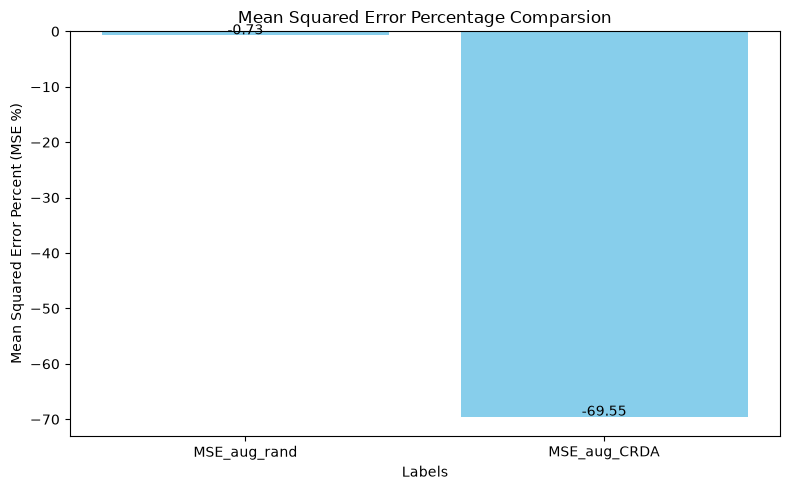

In [51]:
import matplotlib.pyplot as plt

# Example data
MSE_results_labels = ['MSE_aug_rand', 'MSE_aug_CRDA']
MSE_results_values = [MSE_aug_rand_new_percentage, MSE_aug_new_percentage]

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(MSE_results_labels, MSE_results_values, color='skyblue')

plt.title('Mean Squared Error Percentage Comparsion')
plt.xlabel('Labels')
plt.ylabel('Mean Squared Error Percent (MSE %)')

# Add value labels on bars
for i, values in enumerate(MSE_results_values):
    plt.text(i, values + 0.2, f'{values:.2f}', ha='center')

plt.tight_layout()
plt.show()